In [1]:
### import necessary packages ###
import matplotlib.pylab as plt  ##plotting 
from rawice2 import *            ##all modules from rawice.py
import warnings
import numpy as np
import os

warnings.filterwarnings('ignore')

__Note:__ saving the raw acq data will require that you adjust the locations based on where it is on your laptop. This is how I got it through sciserver, but going straight from the weathertop laptop allows you to define the folder path and path normally.

In [2]:
## location of raw acq data
#notebook_path = os.path.abspath("6.13.22 ICE Board Clock analysis.ipyn")
#folder_path = os.path.join(os.path.dirname(notebook_path), "6.13.Run/")
#path = os.path.join(os.path.dirname(notebook_path), "6.13.Run/000017")
## File 000006 is bad for some reason

#path = "G:\\crs\\iceboard\\clocktest\\20261113T132303Z_wvu52_corr\\raw_acq\\000000"
path = "/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000"
#folder_path = "G:\\crs\\iceboard\\clocktest\\20261113T132303Z_wvu52_corr\\raw_acq\\"
folder_path = "/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/"
## load data from file to object 'acq'
acq = raw_acq(path)
#help(raw_acq)
acq.adc_input

#set the input 
#tm4_input = [0,0,12]
#tm5101_input = [0,0,3]

Loaded raw acq HDF5 file ... 


array([7, 8, 9, ..., 4, 5, 6], dtype=uint8)

#Furuno 0 Data 

Checking input [0, 0, 12] ... 


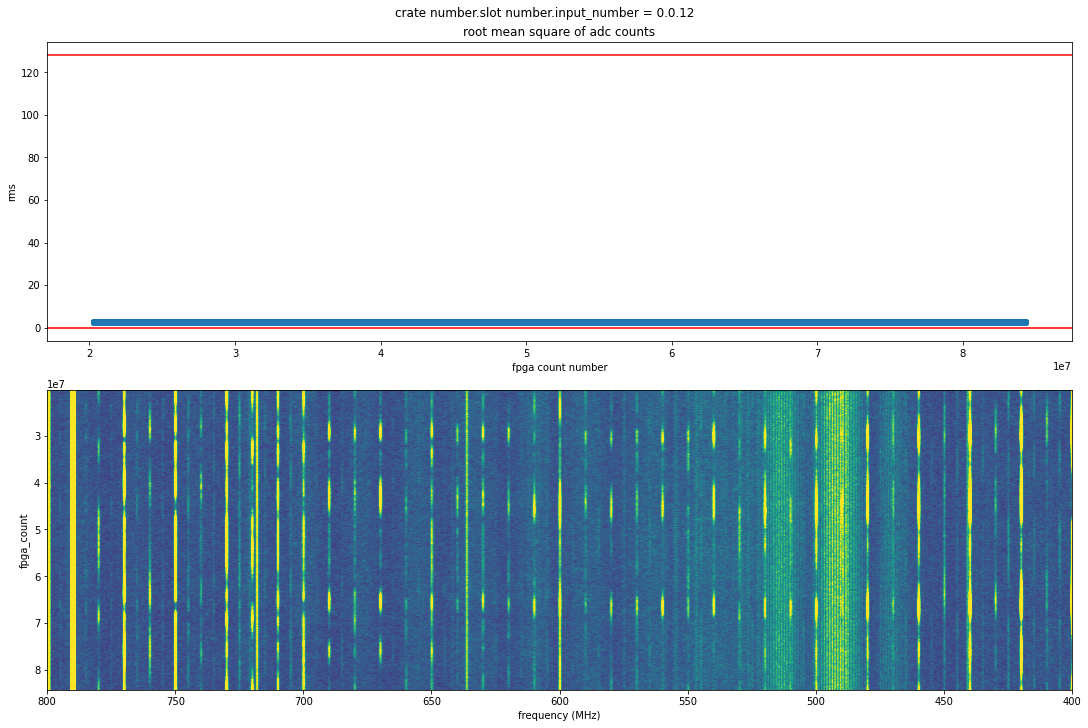

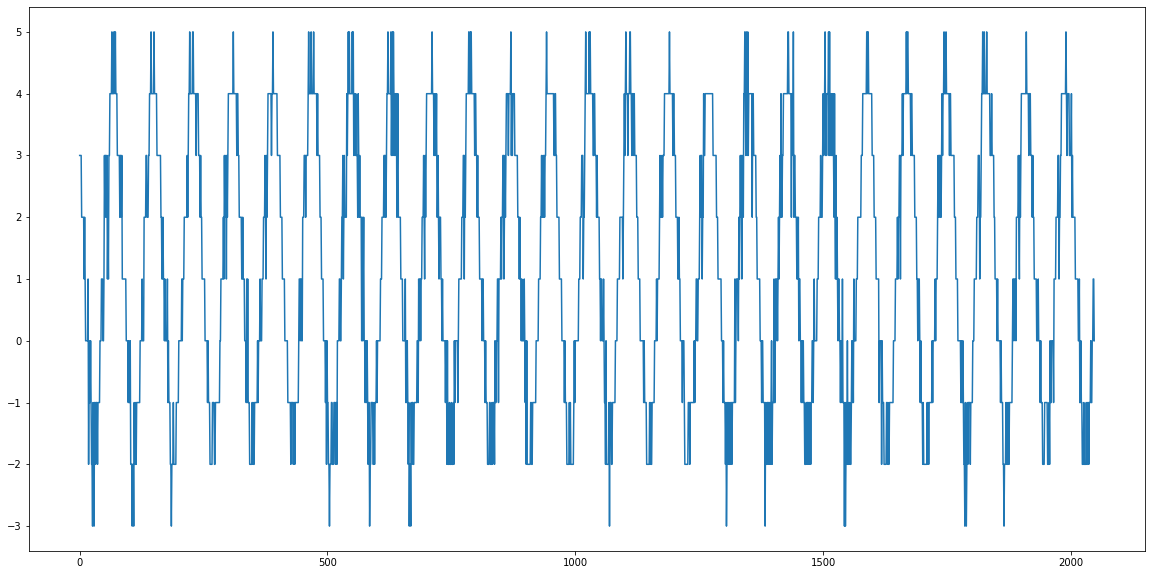

In [3]:
f1 = acq.check_input([0,0,12])
f1.inspect_maser()
f1.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.time_streams[0])

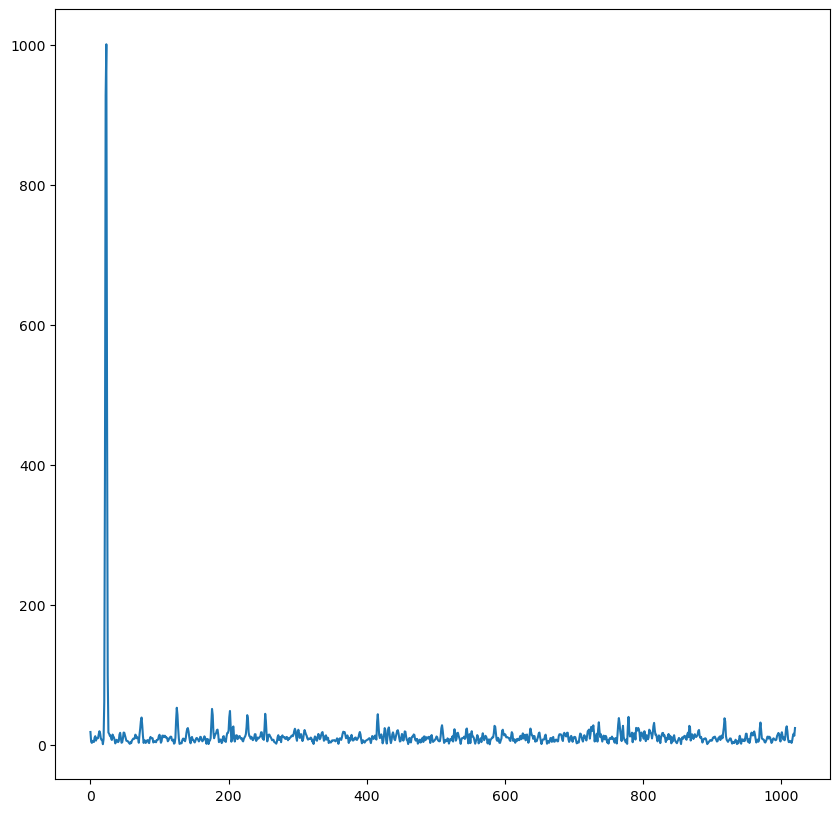

In [5]:
plt.figure(figsize=(10,10))
plt.plot(f1.mag_fft[0][3:])
maxval = max(f1.mag_fft[0][3:])

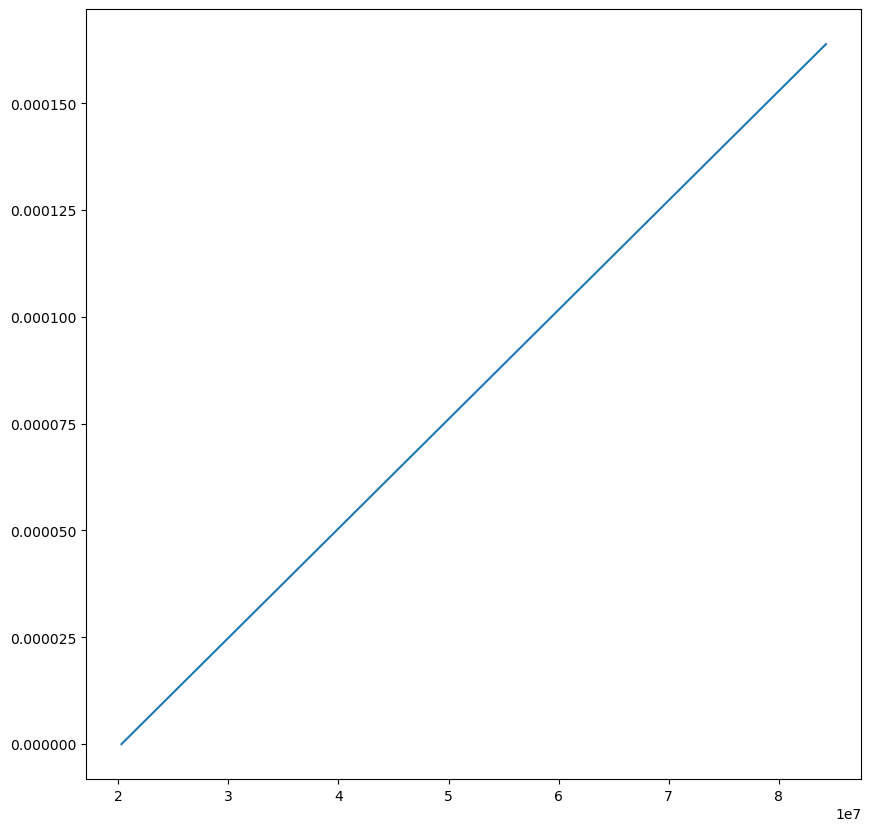

In [6]:
plt.figure(figsize=(10,10))
plt.plot(f1.time_fpga_count, f1.tau)

[-0.39236665  0.85862053  2.10140688 ... -1.41829803 -0.15107392
  1.09072669]


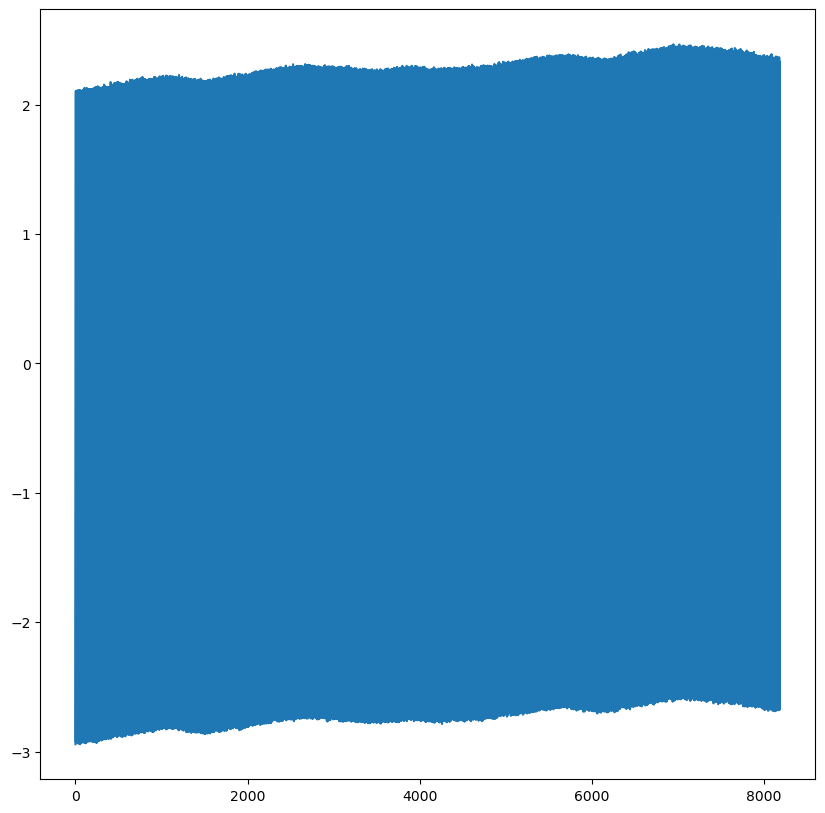

In [7]:
f1_angle_pre = f1.angle_fft[:, 26]
print(f1_angle_pre)

fig, ax = plt.subplots(figsize=(10,10))
plt.plot(f1_angle_pre[3:])


8192
[-0.39236665  0.85862053  2.10140688 ... -1.41829803 -0.15107392
  1.09072669]
[-3.92366648e-01  8.58620528e-01  2.10140688e+00 ...  1.02904392e+04
  1.02917065e+04  1.02929483e+04]


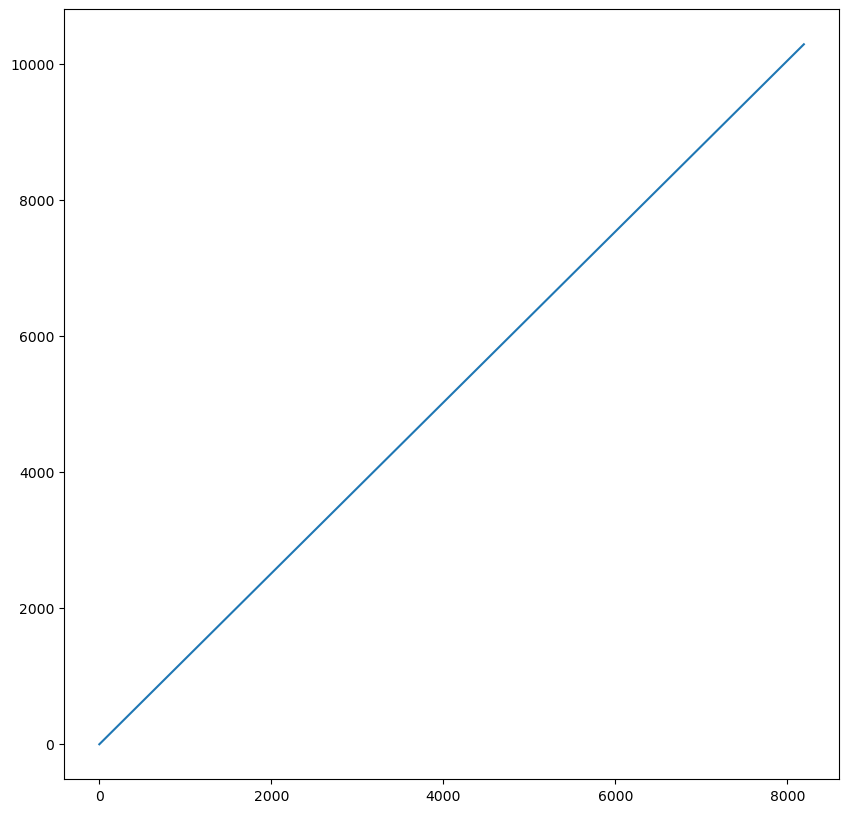

In [8]:
f1_angle_unwrap = np.unwrap(f1_angle_pre)

fig, ax = plt.subplots(figsize=(10,10))
plt.plot(f1_angle_unwrap)
print(len(f1_angle_unwrap))
print(f1_angle_pre)
print(f1_angle_unwrap)

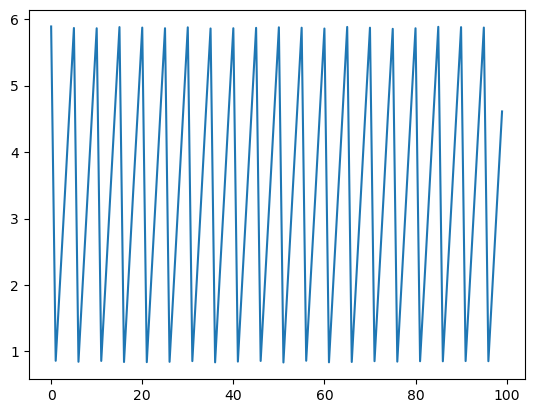

In [9]:
f1_angle_fix = f1_angle_pre % (2*np.pi)

fig, ax = plt.subplots()
plt.plot(f1_angle_fix[:100])

Text(0.5, 1.0, 'TM4 tau')

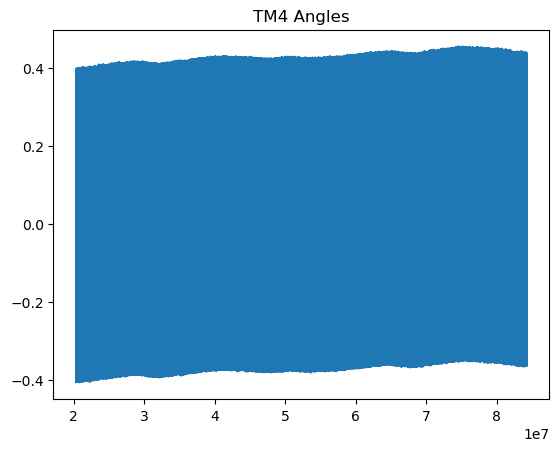

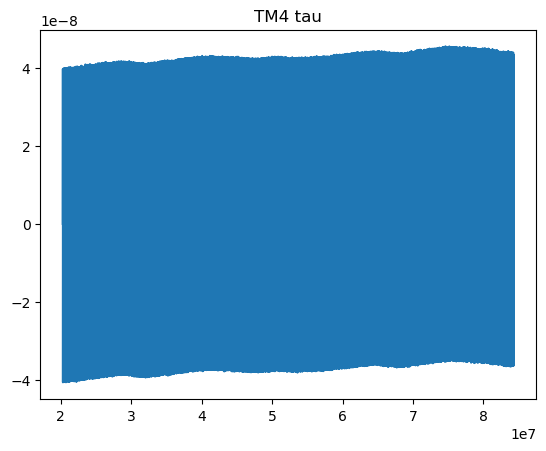

In [10]:
tm4angle = f1.angle_fft[:, 26]/(2 * np.pi)
tm4angle = tm4angle - tm4angle[0]
tm4tau = tm4angle / 10e6

fig, ax1 = plt.subplots()
ax1.plot(f1.time_fpga_count, tm4angle)
ax1.set_title('TM4 Angles')

fig, ax2 = plt.subplots()
ax2.plot(f1.time_fpga_count, tm4tau)
ax2.set_title('TM4 tau')

In [4]:
f1 = analyse_maser(folder_path, [0,0,12])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

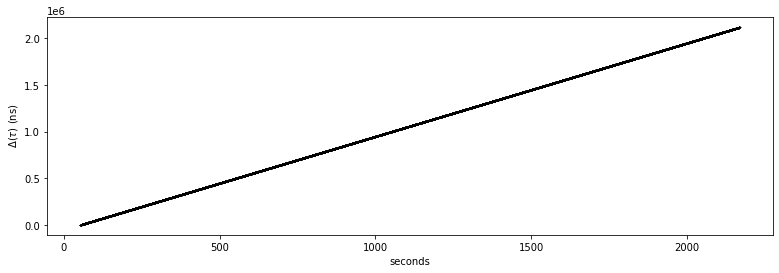

In [5]:
f1_delays = f1.plot_delays()

In [13]:
#f1.get_allan_deviation()

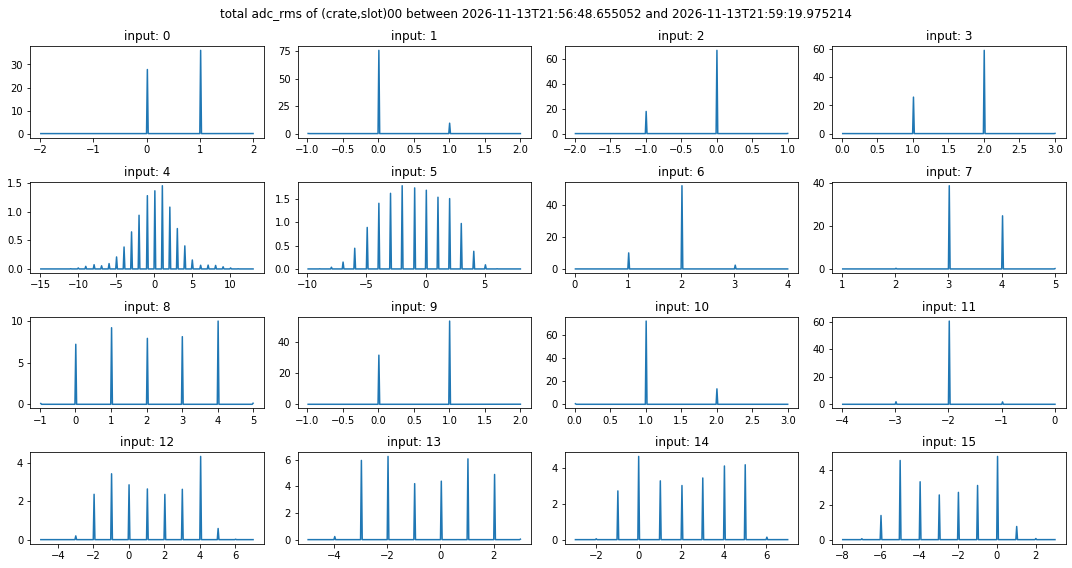

In [6]:
acq.check_iceboard(0, 0)

In [15]:
#acq.diagostics()

Checking input [0, 0, 13] ... 


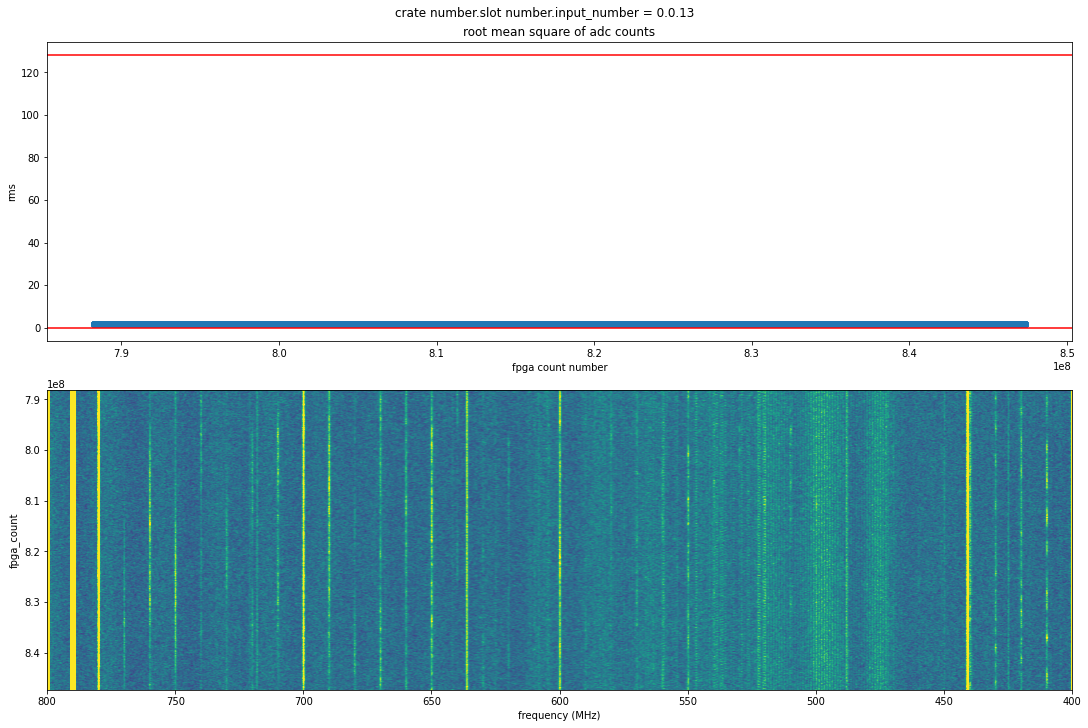

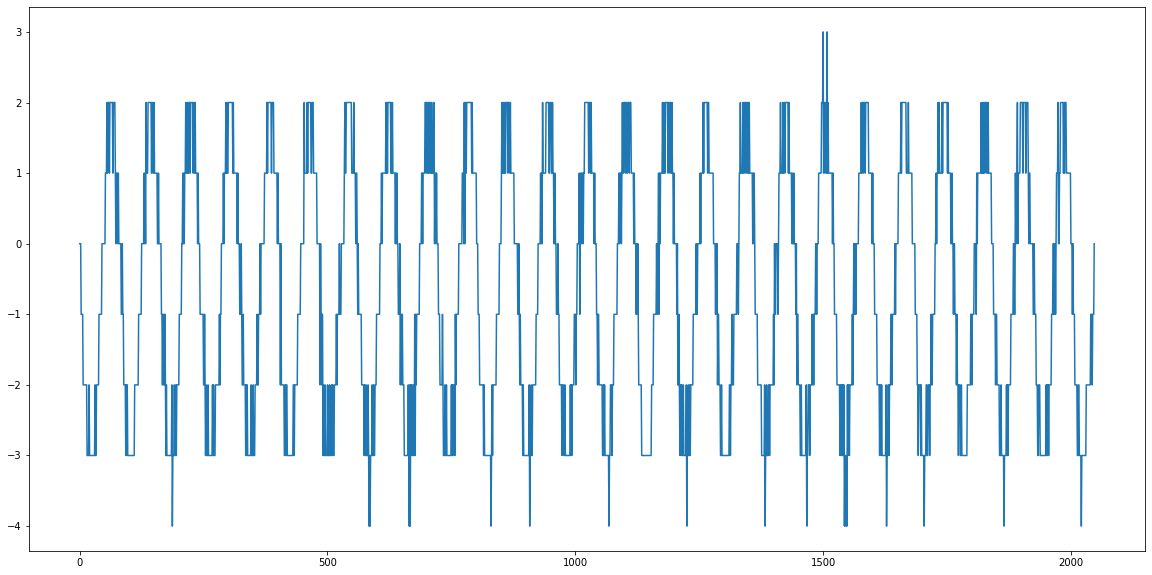

In [7]:
f2 = acq.check_input([0,0,13])
f2.inspect_maser()
f2.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f2.time_streams[1])

Checking input [0, 0, 14] ... 


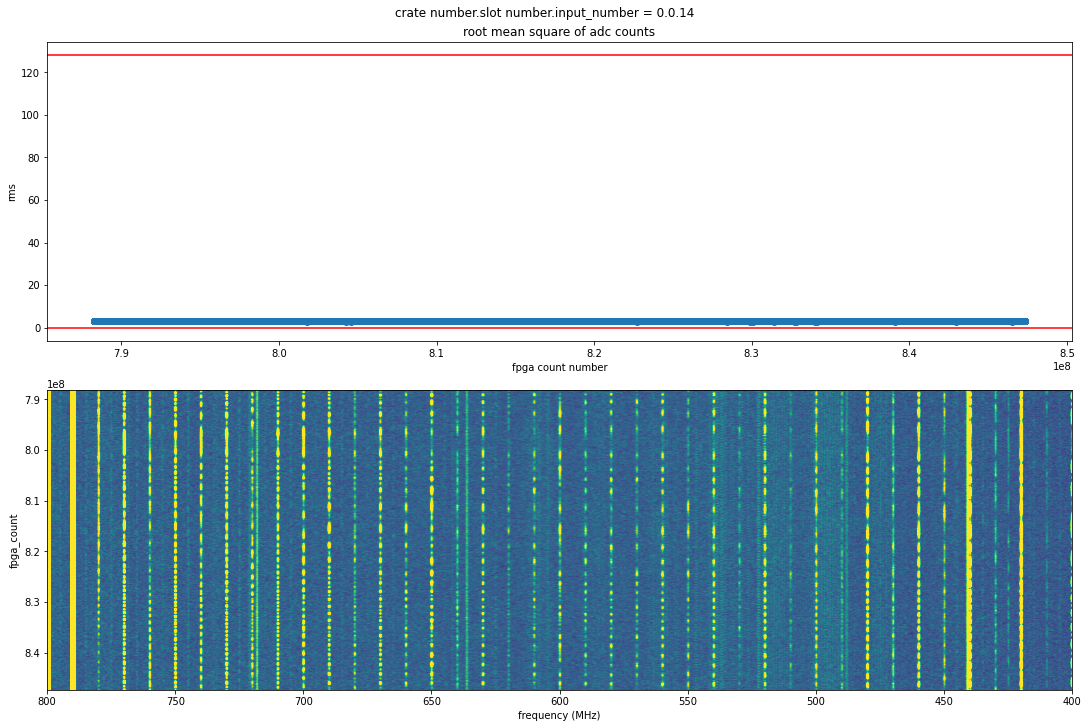

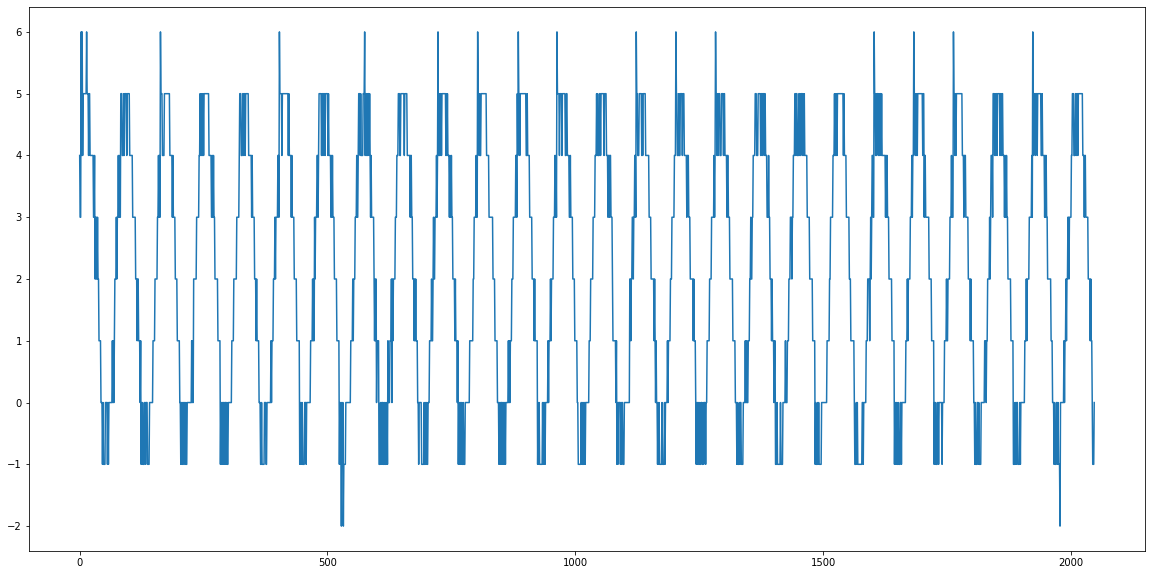

In [8]:
f3 = acq.check_input([0,0,14])
f3.inspect_maser()
f3.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f3.time_streams[1])

Checking input [0, 0, 15] ... 


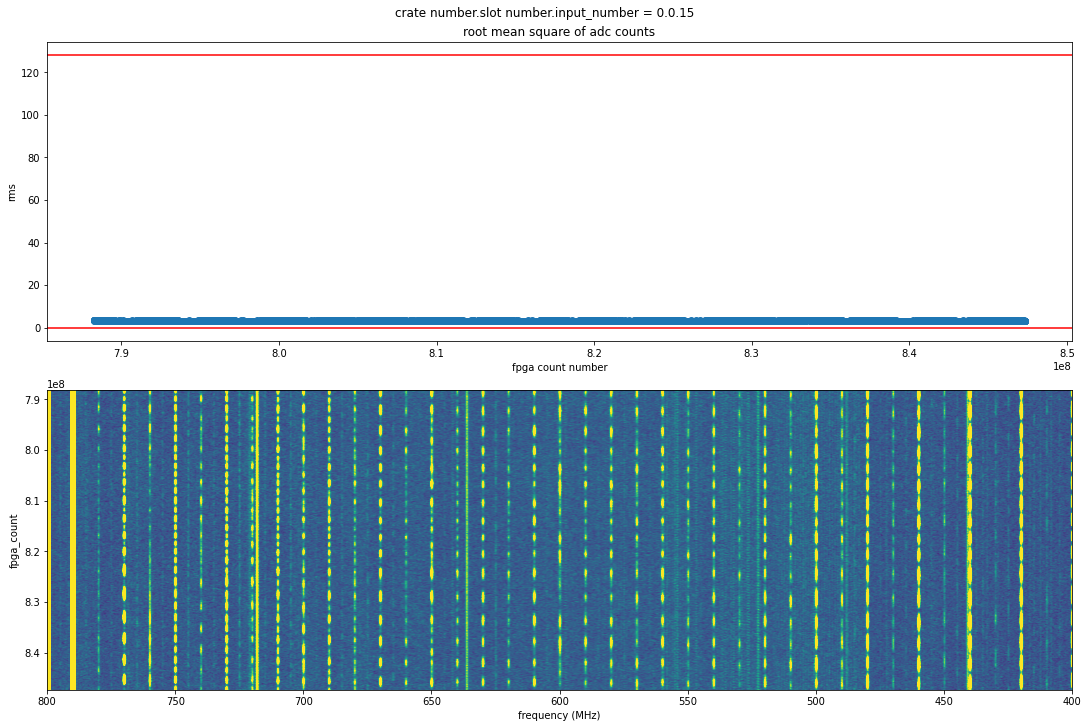

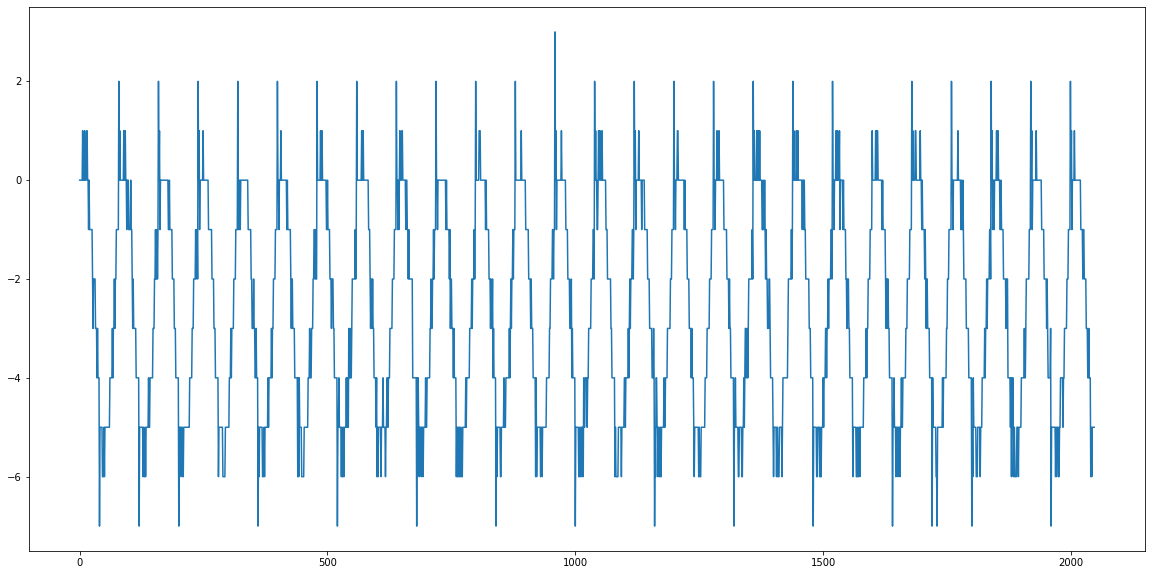

In [9]:
f5 = acq.check_input([0,0,15])
f5.inspect_maser()
f5.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f5.time_streams[1])

Checking input [0, 0, 4] ... 


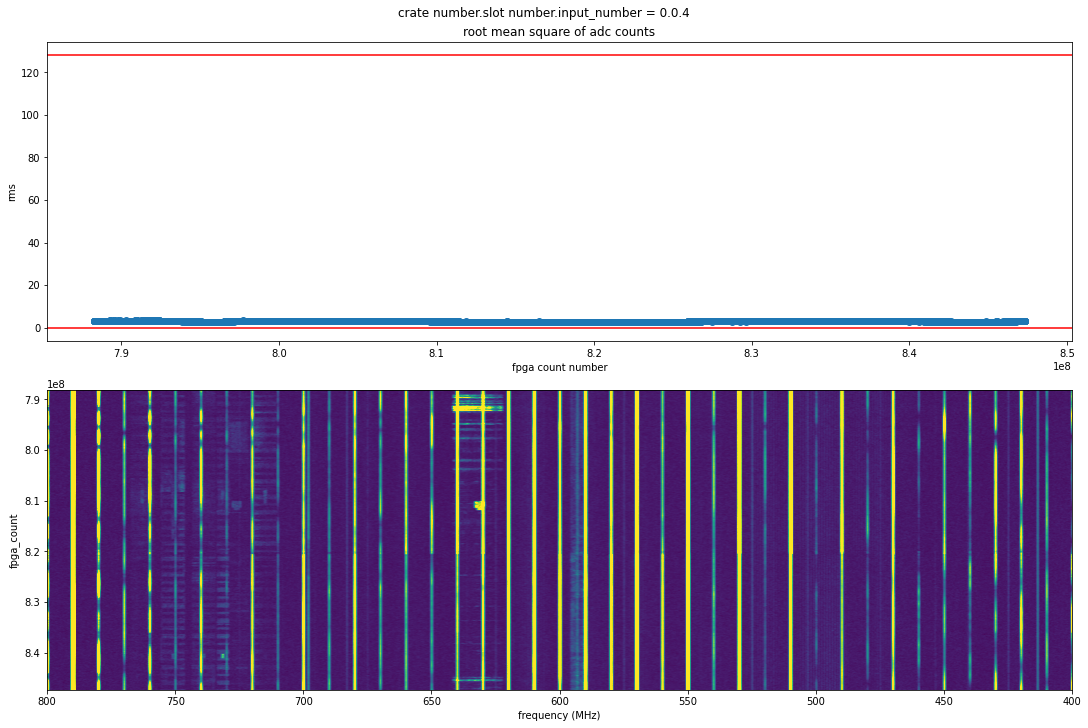

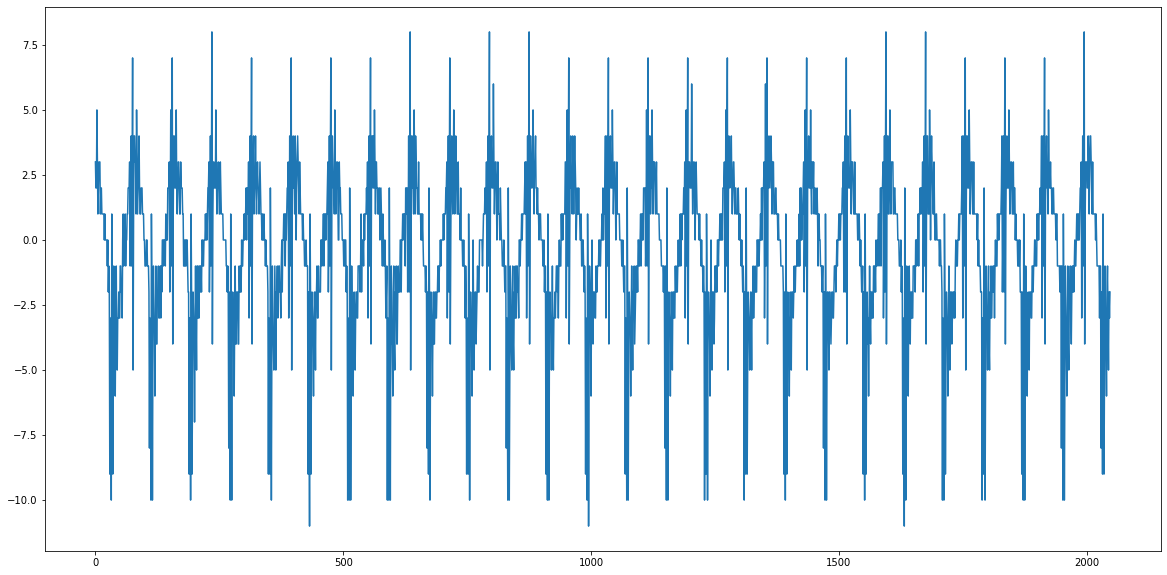

In [10]:
o1 = acq.check_input([0,0,4])
o1.inspect_maser()
o1.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(o1.time_streams[1])

Checking input [0, 0, 5] ... 


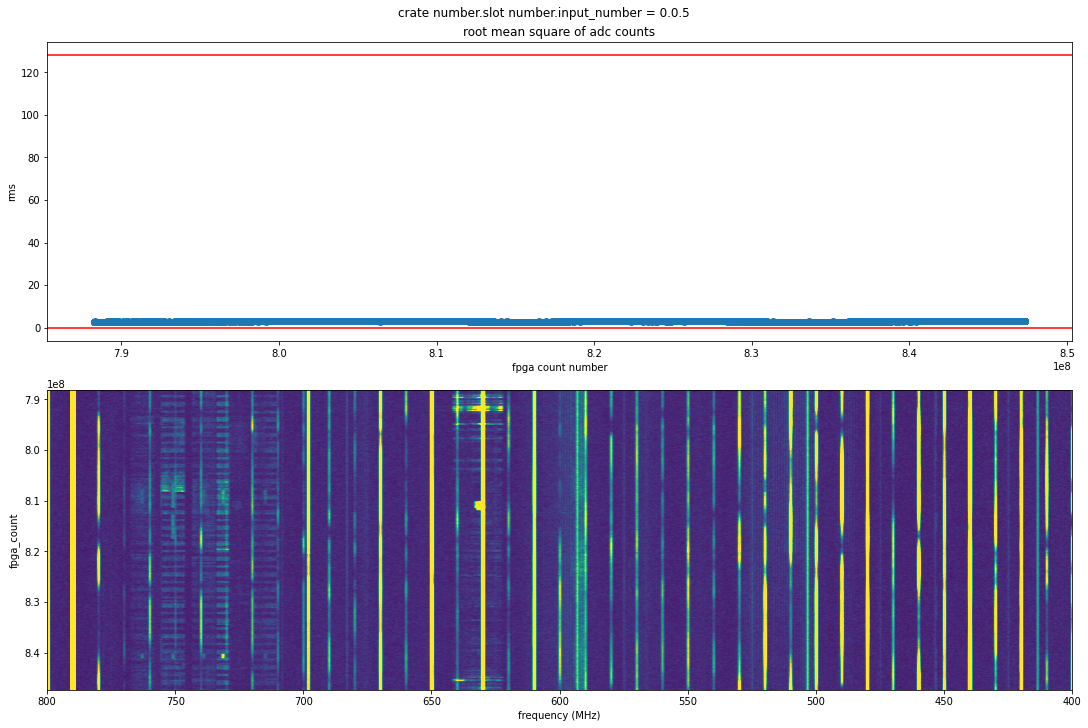

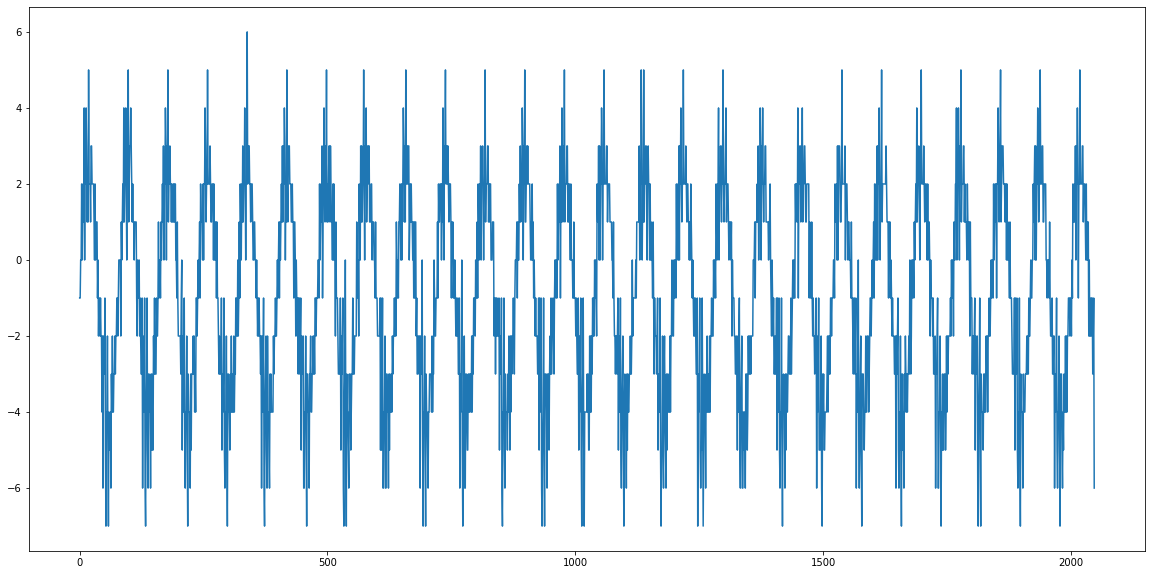

In [11]:
o2 = acq.check_input([0,0,5])
o2.inspect_maser()
o2.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(o2.time_streams[1])

Checking input [0, 0, 8] ... 


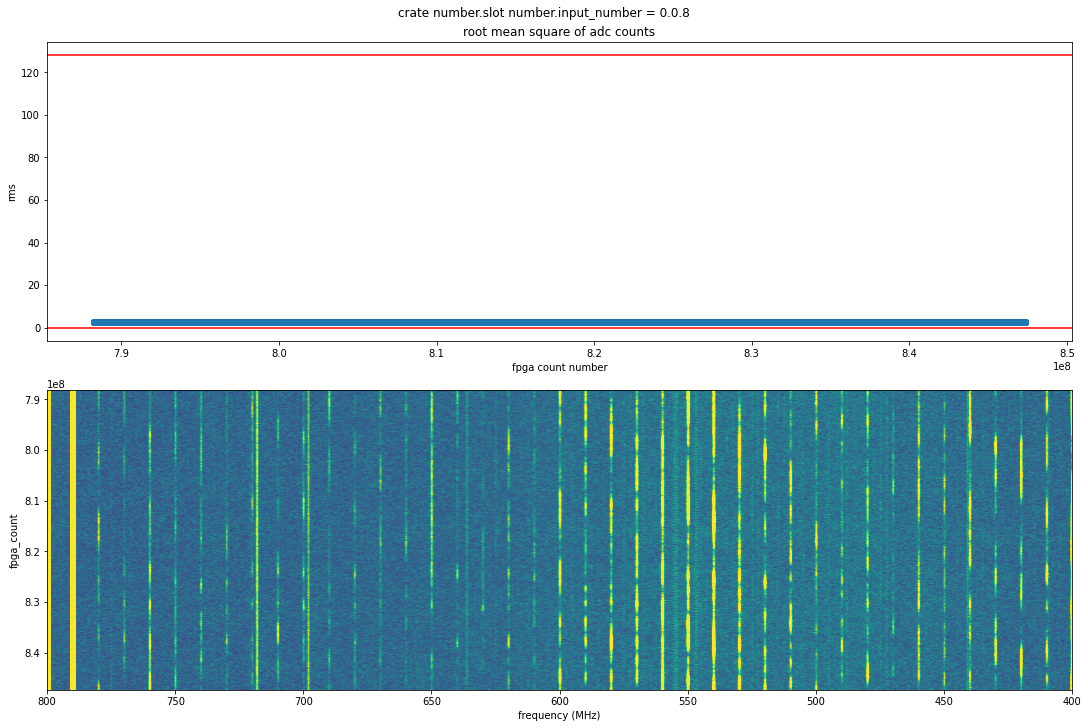

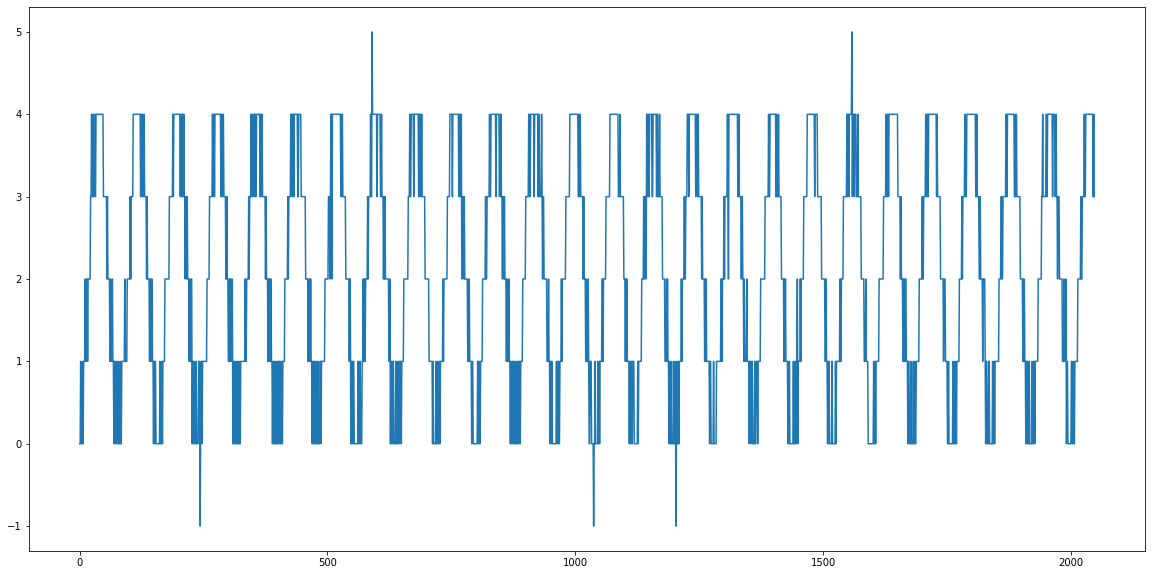

In [12]:
c1 = acq.check_input([0,0,8])
c1.inspect_maser()
c1.plot_single_input_diagnostics()
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(c1.time_streams[1])

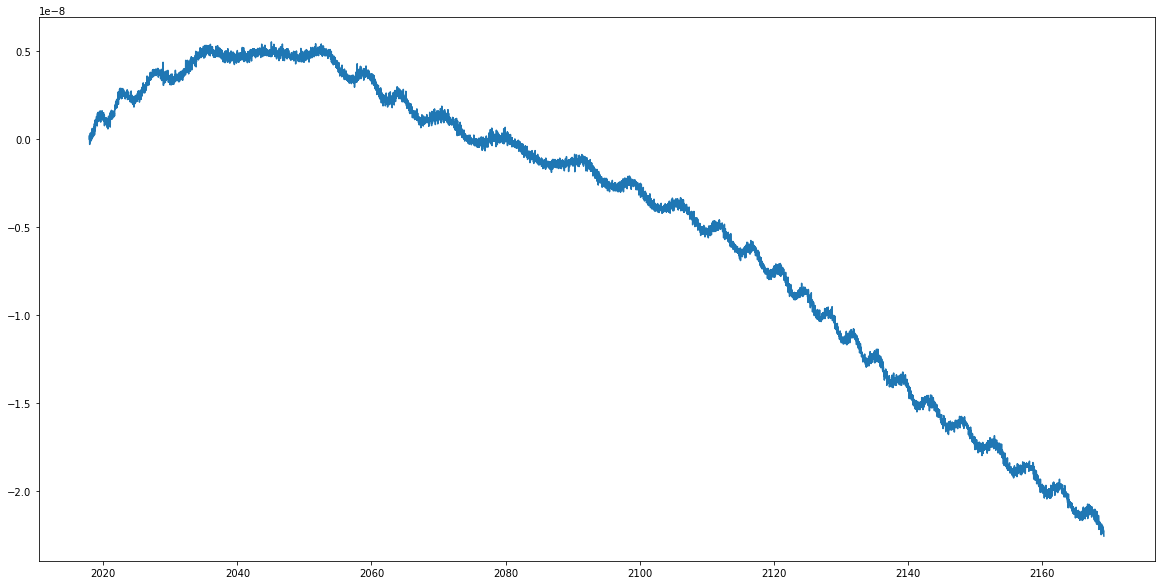

In [14]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f2.time_fpga_count*2.56e-6, f2.tau-f3.tau)

In [23]:
#o1.time_fpga_count

In [15]:
f2 = analyse_maser(folder_path, [0,0,13])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

In [25]:
f1 = analyse_maser(folder_path, [0,0,12])

G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000000
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000001
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000002
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000003
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000004
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000005
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000006
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000007
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000008
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000009
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000010
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000011
G:\crs\iceboard\clocktest\20261113T132303Z_wvu52_corr\raw_acq\000012
Loaded raw acq HDF5 file ... .....................................................................] 0/1

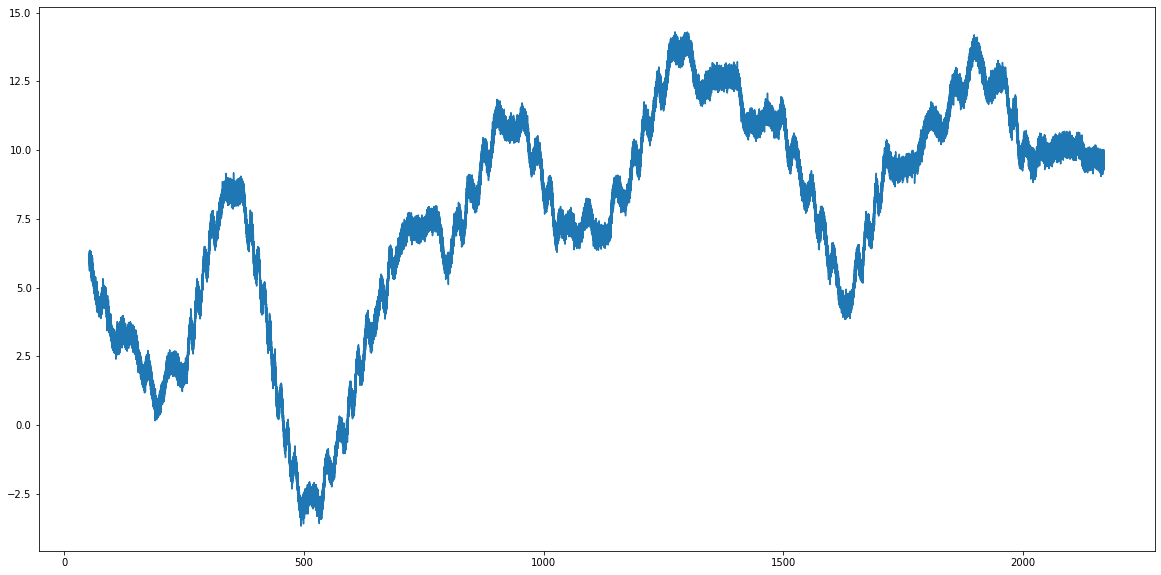

In [16]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f2.taus - f1.taus)

In [56]:
f1.taus

array([-7.75402321e+00,  1.22753199e+01,  3.20519540e+01, ...,
        2.17015811e+06,  2.17017877e+06,  2.17019835e+06], shape=(108511,))

In [17]:
f3 = analyse_maser(folder_path, [0,0,14])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

In [18]:
f5 = analyse_maser(folder_path, [0,0,15])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

In [19]:
o1 = analyse_maser(folder_path, [0,0,4])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

In [20]:
o2 = analyse_maser(folder_path, [0,0,5])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

In [21]:
c1 = analyse_maser(folder_path, [0,0,8])

/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000000
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000001
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000002
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000003
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000004
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000005
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000006
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000007
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000008
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000009
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000010
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000011
/Users/kalyanibhopi94/Downloads/clock_test_II_wvu_hangar/raw_acq/000012
Loaded raw acq HDF5 file ... ...................................

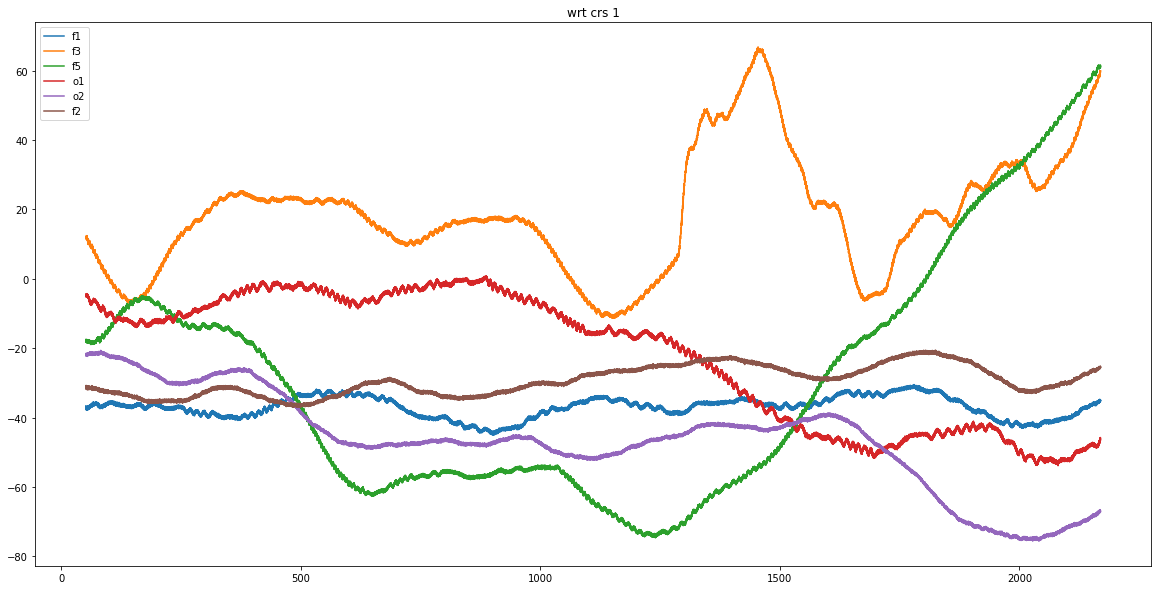

In [36]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - c1.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f3.taus - c1.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - c1.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - c1.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - c1.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - c1.taus, label='f2')
plt.title(f"wrt crs 1")
plt.legend()
#plt.plot(f1.fpgatime*2.56e-6, o2.taus - f1.taus)

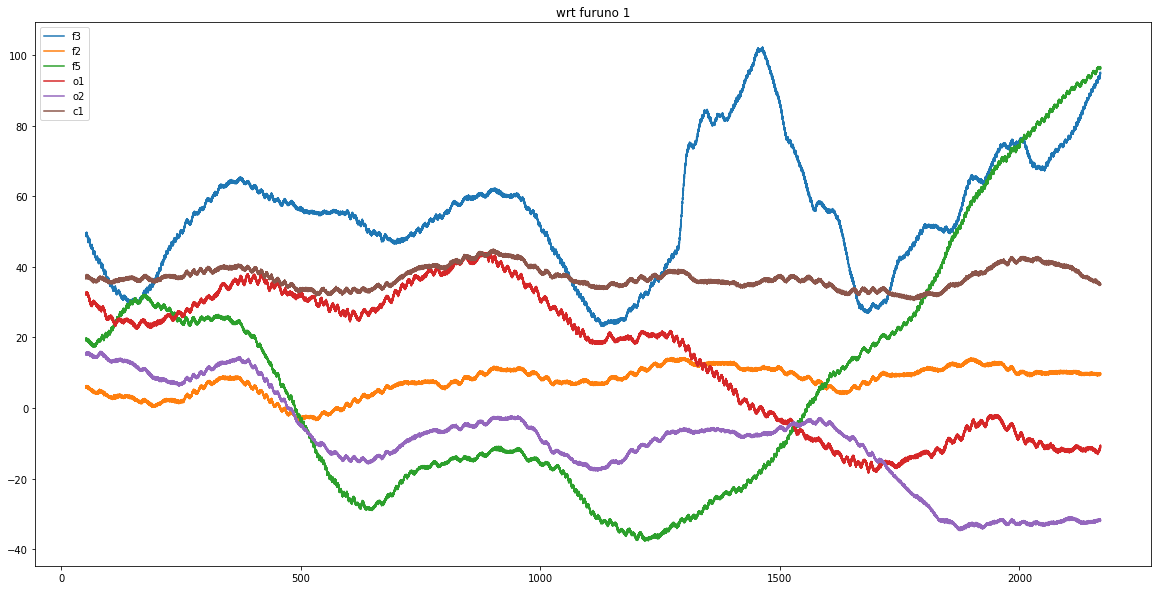

In [35]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f3.taus - f1.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - f1.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - f1.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - f1.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - f1.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - f1.taus, label='c1')
plt.title(f"wrt furuno 1")
plt.legend()

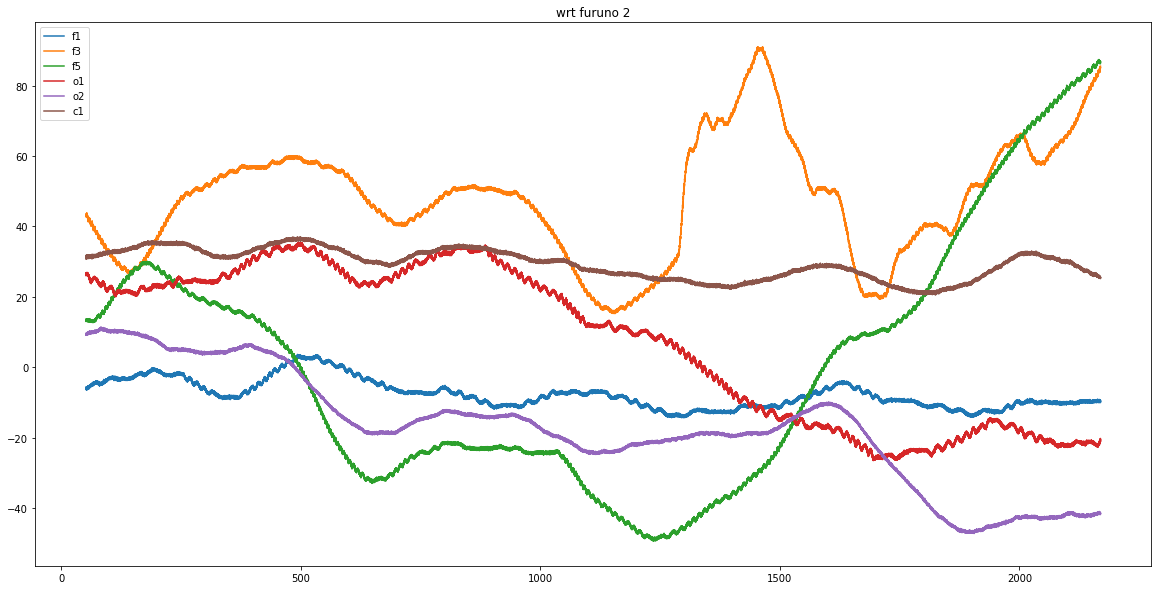

In [34]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - f2.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f3.taus - f2.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - f2.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - f2.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - f2.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - f2.taus, label='c1')
plt.title(f"wrt furuno 2")
plt.legend()

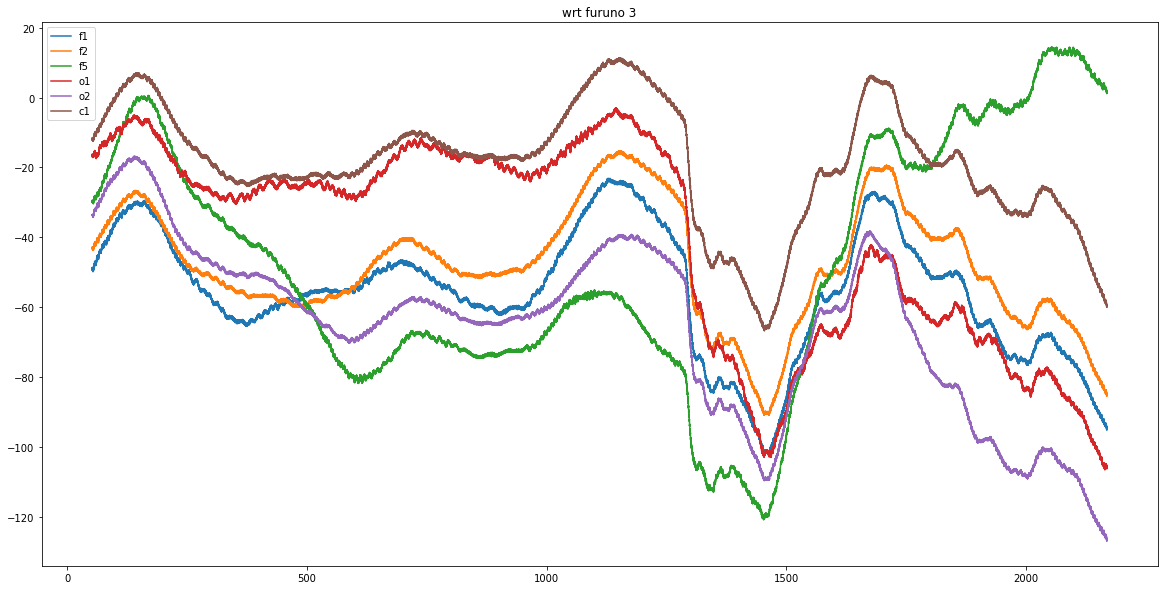

In [33]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - f3.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - f3.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - f3.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - f3.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - f3.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - f3.taus, label='c1')
plt.title(f"wrt furuno 3")
plt.legend()

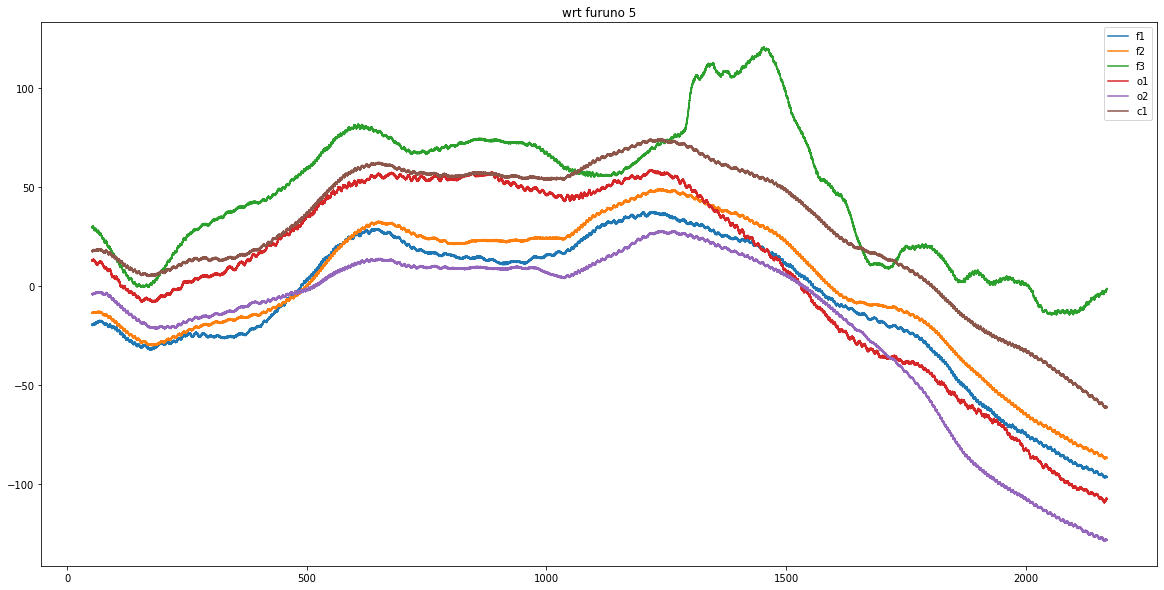

In [32]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - f5.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - f5.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f3.taus - f5.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - f5.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - f5.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - f5.taus, label='c1')
plt.title(f"wrt furuno 5")
plt.legend()

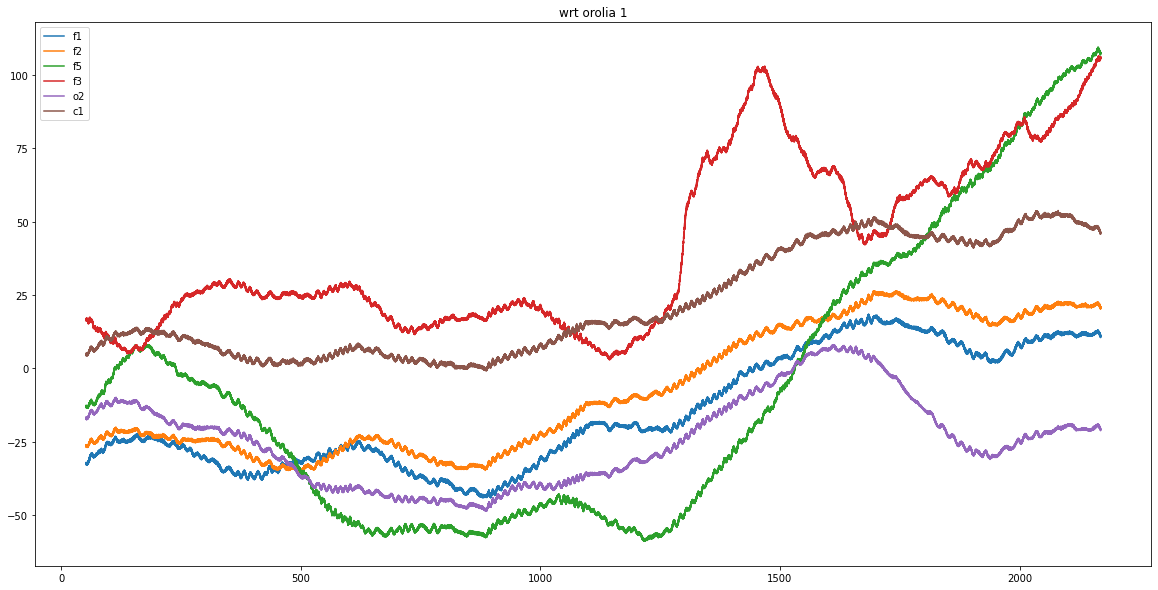

In [31]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - o1.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - o1.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - o1.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, f3.taus - o1.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, o2.taus - o1.taus, label='o2')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - o1.taus, label='c1')
plt.title(f"wrt orolia 1")
plt.legend()

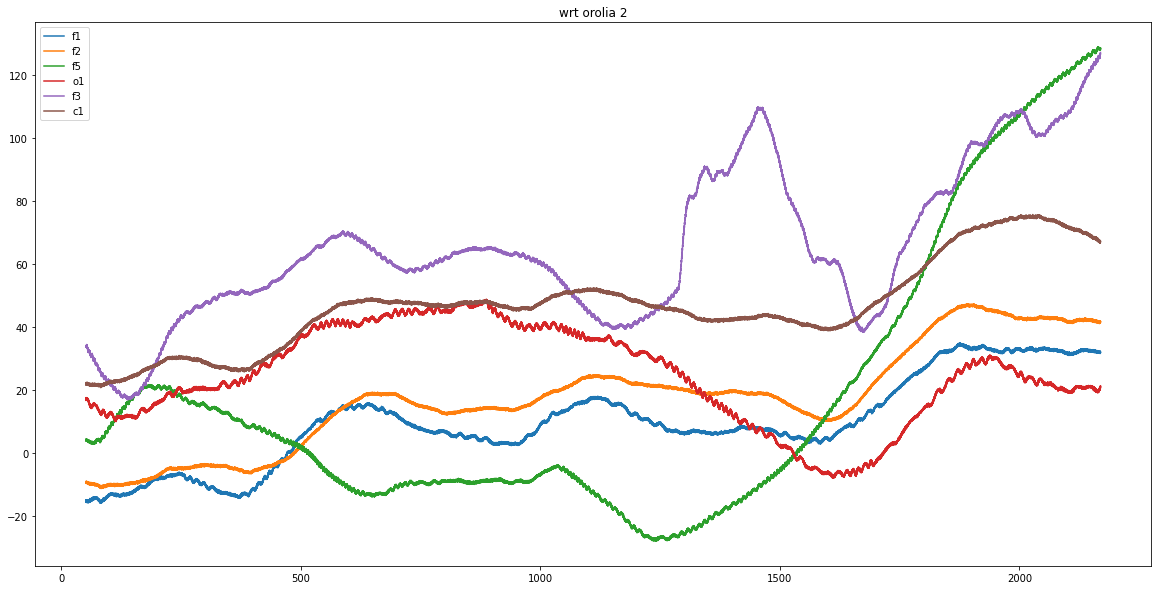

In [30]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus - o2.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f2.taus - o2.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f5.taus - o2.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus - o2.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, f3.taus - o2.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, c1.taus - o2.taus, label='c1')
plt.title(f"wrt orolia 2")
plt.legend()

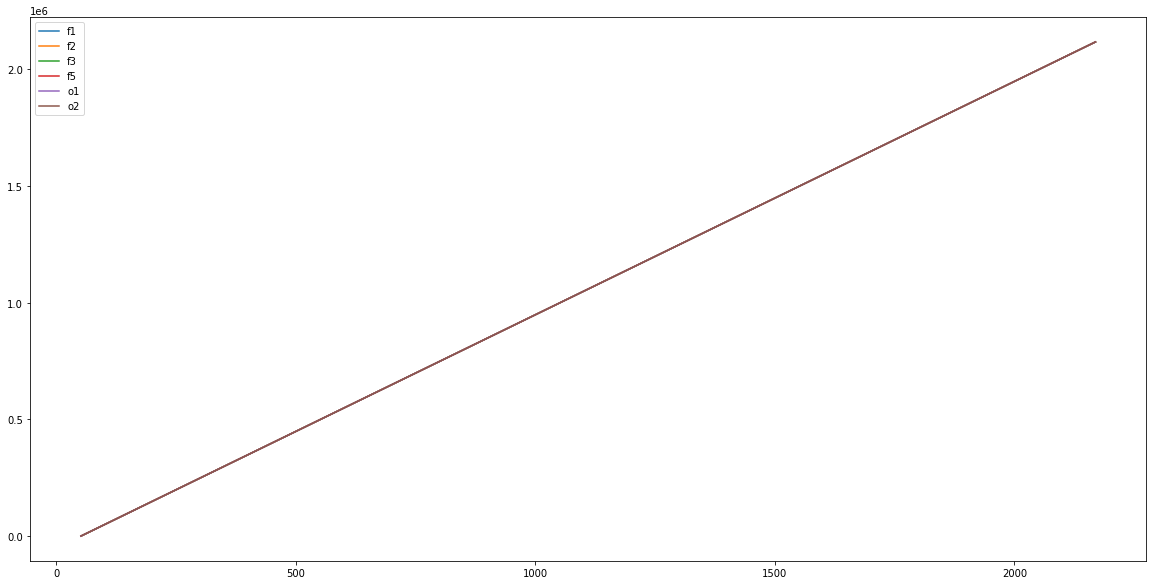

In [44]:
fig, ax = plt.subplots(figsize=(20, 10))
plt.plot(f1.fpgatime*2.56e-6, f1.taus, label='f1')
plt.plot(f1.fpgatime*2.56e-6, f2.taus, label='f2')
plt.plot(f1.fpgatime*2.56e-6, f3.taus, label='f3')
plt.plot(f1.fpgatime*2.56e-6, f5.taus, label='f5')
plt.plot(f1.fpgatime*2.56e-6, o1.taus, label='o1')
plt.plot(f1.fpgatime*2.56e-6, o2.taus, label='o2')
plt.legend()